# 05 Paths for a universe

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamadouyamar/CVineMarketGen/blob/main/examples/05_paths_for_a_universe.ipynb)

<a id="toc"></a>
## Contents

| | |
|---|---|
| **<a href="#s1">1. The problem</a>** | a cross-section cannot answer a question about a year |
| **<a href="#s2">2. How it works</a>** | filter each factor, draw the errors together, run the filters backwards |
| **<a href="#s3">3. What you have</a>** | the workbook and the two histories |
| **<a href="#s4">4. A filter per factor</a>** | notebook 04's rule, seven times |
| **<a href="#s5">5. Is the filter stable</a>** | the fourth moment, and what happens when it is infinite |
| **<a href="#s6">6. The errors drawn together</a>** | the one thing this notebook adds |
| **<a href="#s7">7. Paths</a>** | the factors, then the assets |
| **<a href="#s8">8. Check</a>** | the volatility you asked for, and the dependence at a year |
| **<a href="#s9">9. The answer</a>** | your portfolio's worst year |
| **<a href="#s10">10. What this misses</a>** | and what comes next |

After notebooks 03 and 04. It fits everything from the workbook and the two
histories, so you do not need to have run them. Runtime about two minutes.

---

<a id="s1"></a>
## 1. The problem

<sub><a href="#toc">back to contents</a></sub>

A cross-section cannot answer a question about a year.

Notebook 03 gave you 25,000 months for 68 funds, every moment and correlation
where you wanted it. Notebook 04 gave you one factor with its months in order.
Neither answers the question you actually have.

1. **A drawdown is a sequence.** The worst peak-to-trough of a year depends on
   bad months arriving together. Shuffled months cannot produce it.
2. **A path starts somewhere.** Today the market is calm or it is not, and
   that is information the cross-section threw away.
3. **The factors must fall together.** Filter each one on its own and draw
   their errors separately, and equities and credit stop crashing in the same
   month, which is the dependence notebooks 02 and 03 were built to get right.

---

<a id="s2"></a>
## 2. How it works

<sub><a href="#toc">back to contents</a></sub>

Filter each factor, draw the errors together, run the filters backwards.

Each factor gets a filter from notebook 04, which turns its history into an
i.i.d. generalized error:

$$
f_{k,t} \;\longmapsto\; \varepsilon_{k,t}, \qquad k = 1, \dots, K .
$$

The errors are i.i.d. *in time* but not across factors, so the vector
$\boldsymbol\varepsilon_t = (\varepsilon_{1,t}, \dots, \varepsilon_{K,t})$ is
exactly the kind of object notebooks 01 to 03 draw: exchangeable months with a
dependence structure. The vine is fitted on it instead of on the returns.

Then each filter runs backwards from its own last observed state, and the
assets of notebook 03 follow through their betas:

$$
\boldsymbol\varepsilon_{T+1}, \dots, \boldsymbol\varepsilon_{T+h}
\;\longmapsto\; \mathbf f_{T+1}, \dots, \mathbf f_{T+h}
\;\longmapsto\; r_j = \alpha_j + \boldsymbol\beta_j' \mathbf f + e_j .
$$

Four steps, as always, with one new one in the middle.

| | Step | Where |
|---|---|---|
| 1 | A filter per factor | section 4, the rule of notebook 04 |
| 2 | The errors drawn **jointly** | section 6, the new one |
| 3 | Each filter inverted, the assets carried along | section 7 |
| 4 | Check, then the answer | sections 8 and 9 |

## Import

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "examples" else os.getcwd()
sys.path.insert(0, ROOT)
try:
    import cvinemarketgen
except ImportError:                        # Google Colab
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/mamadouyamar/CVineMarketGen.git", "openpyxl"], check=True)
    import cvinemarketgen
print("cvinemarketgen", cvinemarketgen.__version__)

from cvinemarketgen import (load_etf_monthly, load_factor_data, MarketSpec, FactorMarket, Targets,
                            CVineMarket, Paths, select_dynamics, fit_johnson_su, parse_spec)
from scipy import stats
import seaborn as sns
A = lambda m: m * 1200                     # monthly mean -> percent a year
V = lambda v: v * np.sqrt(12) * 100        # monthly vol  -> percent a year
INPUTS = os.path.join(ROOT, "examples", "inputs")
WORKBOOK = os.path.join(INPUTS, "universe_paths.xlsx")
if not os.path.exists(WORKBOOK):           # Google Colab: the repository is not on disk
    import urllib.request
    os.makedirs(INPUTS, exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/mamadouyamar/CVineMarketGen/main/examples/inputs/universe_paths.xlsx", WORKBOOK)

cvinemarketgen 0.3.0


---

<a id="s3"></a>
## 3. What you have

<sub><a href="#toc">back to contents</a></sub>

The workbook and the two histories.

The workbook is `universe_paths.xlsx`: the universe of notebook 03 without the
objects that have no history. A filter is estimated from a series, so the
Illiquidity factor cannot have one, and the two funds whose only exposure to
it was a stated beta cannot be carried along a path. Notebook 03 and
[recipe 6](recipes/r6_factor_without_history.ipynb) are where those belong.

That leaves 68 listed funds on 7 factors. One call fits them, exactly as in
notebook 03, with the Fleishman generator: the factor dependence is refitted
on the errors in section 6 anyway.

The workbook and the two histories in.

In [2]:
spec = MarketSpec.read(WORKBOOK)
tickers = list(spec.assets["ticker"])
R = load_etf_monthly(tickers, start="2007-04", cache=os.path.join(ROOT, "data", "etf_cache_universe.csv"))[tickers]
F = load_factor_data(cache=os.path.join(ROOT, "data", "factors_cache.csv"))
idx = R.index.intersection(F.index); R, F = R.loc[idx], F.loc[idx]
sim = FactorMarket(R, F, spec, generator="fleishman").fit()
FAC = sim.model.factors
print(f"{len(tickers)} assets on {len(FAC)} factors, {len(R)} months, median R2 {sim.model.r2.median():.2f}")

ETF returns read from cache /Users/mamadouthioub/Desktop/CopulaGenerator/CVineMarketGen/data/etf_cache_universe.csv: 232 months, 2007-06 to 2026-09
factor data read from cache /Users/mamadouthioub/Desktop/CopulaGenerator/CVineMarketGen/data/factors_cache.csv: 244 months, 2006-04 to 2026-07
68 assets on 7 factors, 230 months, median R2 0.73


Same universe as notebook 03 minus the two synthetic funds, and the same
median $R^2$ of 0.73. Everything from here on is about the seven factors.

---

<a id="s4"></a>
## 4. A filter per factor

<sub><a href="#toc">back to contents</a></sub>

Notebook 04's rule, seven times.

The rule is notebook 04's and nothing else: the parametric-bootstrap
goodness-of-fit test on every candidate, then the lowest BIC among those that
pass.

The grid is smaller than notebook 04's twenty-eight. A constant mean, and a
variance that is constant or a GARCH(1,1) or a GJR(1,1), plus a two-regime
hidden Markov model, with $B = 30$ bootstrap replications. Twenty-eight
candidates at $B = 100$ took notebook 04 eight minutes for one factor, and
seven factors need a grid that fits in half a minute.

Select, for all seven.

In [3]:
t0 = time.time()
sel = select_dynamics(F[FAC], candidates=("const", "garch", "gjr"), means=("const",), pq=(1, 1),
                      states=(2,), B=30, seed=0, verbose=False)
print(f"{len(FAC)} factors, 4 candidates each, fitted and tested in {time.time() - t0:.0f} s")
sel.report[["model", "n_params", "bic"]]

7 factors, 4 candidates each, fitted and tested in 23 s


,model,n_params,bic
asset,,,
Equity DM,"Const-GJR(1,1)",5,-786.000510
Equity EM,Const-Const,2,-930.773004
Real premia,"Const-GARCH(1,1)",4,-1206.838698
Inflation,"Const-GJR(1,1)",5,-1378.258032
Credit,"Const-GJR(1,1)",5,-1146.836761
Commodity,"Const-GARCH(1,1)",4,-681.876539
Small cap,Const-Const,2,-1029.666853


Three factors take the GJR, two take a plain GARCH, and Equity EM and Small
cap take a constant variance: their squares carry nothing for a filter to
remove. Equity DM picks the same Const-GJR(1,1) notebook 04 chose from the
full grid.

---

<a id="s5"></a>
## 5. Is the filter stable

<sub><a href="#toc">back to contents</a></sub>

The fourth moment, and what happens when it is infinite.

Notebook 04 ended on a warning and promised to return to it here. A GARCH
recursion has a finite fourth moment, and so a finite kurtosis, only if

$$
\mathbb{E}\big[(\alpha\,\varepsilon^2 + \gamma\,\varepsilon^2\,\mathbf 1\{\varepsilon<0\} + \beta)^2\big] < 1 ,
$$

and nothing in the selection enforces it. The likelihood is finite either way,
and the goodness-of-fit test looks at 230 standardized errors, which say
nothing about a moment of the process.

So compute it for every selected model, and find the cheapest model per factor
that passes the test *and* satisfies it.

The condition, and the alternative.

In [4]:
def fourth_moment(m):
    """E[(alpha e^2 + gamma e^2 1{e<0} + beta)^2]: below 1 the recursion has a finite kurtosis."""
    if getattr(m, "kind", "garch") == "hmm":
        return np.nan
    P = m.params
    al = P["alpha"][0] if len(P["alpha"]) else 0.0
    be = P["beta"][0] if len(P["beta"]) else 0.0
    k = float(pd.Series(m.filter()).kurt() + 3.0)
    return (al ** 2 + al * P["gamma"] + P["gamma"] ** 2 / 2) * k + 2 * (al + P["gamma"] / 2) * be + be ** 2

rows = {}
for f in FAC:
    ok = sel.candidates[(sel.candidates["asset"] == f) & sel.candidates["passed"]].sort_values("bic")
    fits = {r["model"]: parse_spec(r["model"].lower()).fit(F[f]) for _, r in ok.iterrows() if "HMM" not in r["model"]}
    stable = next(((r["model"], r["bic"]) for _, r in ok.iterrows()
                   if r["model"] in fits and fourth_moment(fits[r["model"]]) < 1), None)
    rows[f] = {"selected": ok.iloc[0]["model"], "its fourth moment": fourth_moment(fits.get(ok.iloc[0]["model"])),
               "cheapest with a finite kurtosis": stable[0] if stable else "(none)",
               "BIC given up": (stable[1] - ok.iloc[0]["bic"]) if stable else np.nan}
stab = pd.DataFrame(rows).T
stab.round(2)

,selected,its fourth moment,cheapest with a finite kurtosis,BIC given up
Equity DM,"Const-GJR(1,1)",1.021408,"Const-GARCH(1,1)",14.529442
Equity EM,Const-Const,0.0,Const-Const,0.0
Real premia,"Const-GARCH(1,1)",0.719267,"Const-GARCH(1,1)",0.0
Inflation,"Const-GJR(1,1)",1.142894,Const-Const,72.327847
Credit,"Const-GJR(1,1)",5.865962,Const-Const,101.412691
Commodity,"Const-GARCH(1,1)",0.981574,"Const-GARCH(1,1)",0.0
Small cap,Const-Const,0.0,Const-Const,0.0


Three of the seven selected models fail it. Equity DM and Inflation are just
over the line; Credit is nowhere near it.

The cost of the stable choice is not small, and the last column prices it.
Equity DM drops from the GJR to a plain GARCH. Inflation and Credit have no
GARCH that both passes the test and satisfies the condition, so they fall back
to a constant variance, which for those two means giving up the clustering
itself.

What the violation does, factor by factor, on each factor alone.

In [5]:
def jsu_paths(model, n_paths, horizon, seed):
    """One factor's own paths: errors from a Johnson SU fitted to its generalized error."""
    e = pd.Series(np.asarray(model.filter(), float))
    p = fit_johnson_su(float(e.skew()), max(float(e.kurt() + 3), 3.1 + 2 * float(e.skew()) ** 2))
    z = np.random.default_rng(seed).standard_normal((n_paths, horizon))
    u = p["xi"] + p["lambda"] * np.sinh((z - p["gamma"]) / p["delta"])
    return model.unfilter((u - u.mean()) / u.std())

rows = {}
for f in ("Equity DM", "Inflation", "Credit"):
    for lab, s in [("selected", stab.loc[f, "selected"]), ("finite kurtosis", stab.loc[f, "cheapest with a finite kurtosis"])]:
        m = parse_spec(s.lower()).fit(F[f]); P = jsu_paths(m, 2000, 12, 3)
        rows[(f, f"{lab}: {s}")] = {"fourth moment": fourth_moment(m), "pooled kurtosis of the paths": stats.kurtosis(P.ravel()) + 3,
                                    "worst simulated month (%)": P.min() * 100, "worst month in the sample (%)": F[f].min() * 100}
pd.DataFrame(rows).T.round(2)

fourth moment  pooled kurtosis of the paths  worst simulated month (%)  worst month in the sample (%)
Equity DM selected: Const-GJR(1,1)                    1.02                         18.61                     -93.10                         -19.51
          finite kurtosis: Const-GARCH(1,1)           0.85                          6.22                     -45.56                         -19.51
Inflation selected: Const-GJR(1,1)                    1.14                         17.47                     -25.26                          -5.71
          finite kurtosis: Const-Const                0.00                          8.15                     -10.81                          -5.71
Credit    selected: Const-GJR(1,1)                    5.87                        628.69                    -199.73                         -15.30
          finite kurtosis: Const-Const                0.00                         13.25                     -28.26                         -15.30

Credit's selected model produces a month past $-100$ percent, which is not a
severe scenario but an arithmetic impossibility, and its pooled kurtosis says
the same thing: the recursion is running away. Equity DM has the same disease,
milder.

With the condition satisfied every worst month is severe and possible. The rest
of the notebook uses the stable set.

In [6]:
STABLE = {f: stab.loc[f, "cheapest with a finite kurtosis"].lower() for f in FAC}
STABLE

{'Equity DM': 'const-garch(1,1)',
 'Equity EM': 'const-const',
 'Real premia': 'const-garch(1,1)',
 'Inflation': 'const-const',
 'Credit': 'const-const',
 'Commodity': 'const-garch(1,1)',
 'Small cap': 'const-const'}

---

<a id="s6"></a>
## 6. The errors drawn together

<sub><a href="#toc">back to contents</a></sub>

The one thing this notebook adds.

Now the filters are fixed, and the vine is fitted on the layer they leave
behind instead of on the returns. One call filters the seven histories, takes
the moments and the dependence of the errors as its targets, and selects a
copula per pair exactly as notebook 02 did.

Fit it.

In [7]:
t0 = time.time()
cv = CVineMarket(Targets.from_history(F[FAC]), central="Equity DM", dynamics=STABLE).fit()
print(f"filtered and fitted in {time.time() - t0:.0f} s | the generator now draws the {cv.layer} layer")
cv.edges[cv.edges["tree"] == 1]

filtered and fitted in 89 s | the generator now draws the residuals layer


,tree,edge,selected family,parameters
0,1,"Equity EM , Equity DM",gaussian 0°,theta=0.044
1,1,"Real premia , Equity DM",student 0°,"rho=0.247, df=4.6"
2,1,"Inflation , Equity DM",student 0°,"rho=0.485, df=5.2"
3,1,"Credit , Equity DM",gaussian 0°,theta=0.571
4,1,"Commodity , Equity DM",student 0°,"rho=0.438, df=4.9"
5,1,"Small cap , Equity DM",gaussian 0°,theta=0.262


The first tree of the error vine is not the first tree of notebook 03's return
vine. Credit against Equity DM is a Gaussian here where the returns gave a
Student t: once each factor's own volatility clustering is removed, what is
left of their joint tail is thinner. Three pairs keep a Student t.

Draw the errors, then shuffle each column on its own to see what the vine is doing.

In [8]:
NP, H = 2000, 12
Z = cv.simulate(NP * H, seed=1)
rng = np.random.default_rng(7)
Zi = pd.DataFrame({c: rng.permutation(Z[c].values) for c in Z.columns})      # same marginals, dependence destroyed
pd.DataFrame({"history": cv.fit_targets.corr["Equity DM"], "drawn jointly": Z.corr()["Equity DM"],
              "drawn one at a time": Zi.corr()["Equity DM"]}).drop("Equity DM").round(3)

,history,drawn jointly,drawn one at a time
Equity EM,0.058,0.049,0.005
Real premia,0.236,0.241,-0.005
Inflation,0.469,0.461,0.004
Credit,0.545,0.539,0.001
Commodity,0.421,0.434,-0.006
Small cap,0.258,0.253,-0.013


Drawn jointly, the error correlations are the history's to the third decimal.
Shuffled, every one of them collapses to zero.

That last column is what filtering one factor at a time and drawing its errors
separately would give you, and it is the reason this notebook exists.

---

<a id="s7"></a>
## 7. Paths

<sub><a href="#toc">back to contents</a></sub>

The factors, then the assets.

Each filter runs backwards from its own last observed state, which turns the
error months into factor months in order. The assets follow through the betas
of section 3, with their own residuals added as in notebook 03.

Both versions are built, the joint errors and the shuffled ones, so every
check below has its counterfactual.

Factors, then assets.

In [9]:
paths_of = lambda D: Paths(cv.dynamics.unfilter(D.values.reshape(NP, H, len(FAC))), FAC)
Pf, Pf_indep = paths_of(Z), paths_of(Zi)
Pa, Pa_indep = sim.model.simulate(Pf, seed=2), sim.model.simulate(Pf_indep, seed=2)
print(f"{NP} paths of {H} months | factors {Pf.array.shape} | assets {Pa.array.shape}")

2000 paths of 12 months | factors (2000, 12, 7) | assets (2000, 12, 68)


---

<a id="s8"></a>
## 8. Check

<sub><a href="#toc">back to contents</a></sub>

The volatility you asked for, and the dependence at a year.

A reader of notebook 03 will ask the obvious question first: do the 68 assets
still have the volatility the workbook asked for? Pool every month of every
path and compare.

In [10]:
chk = sim.check(n=20000, seed=3)["assets"]
target = chk["vol target"].astype(float)
pooled = pd.Series(Pa.array.reshape(-1, len(tickers)).std(axis=0), index=tickers)
ratio = pooled / target
show = ["SPY", "TLT", "GLD", "HYG", "KBE", "DBC"]
m = cv.dynamics.models["Commodity"]; P = m.params
persistence = P["alpha"][0] + P["gamma"] / 2 + P["beta"][0]
print("all %d assets: median ratio %.2f, from %.2f (%s) to %.2f (%s)"
      % (len(tickers), ratio.median(), ratio.min(), ratio.idxmin(), ratio.max(), ratio.idxmax()))
print("Commodity's filter: last observed volatility %.0f%%/yr, unconditional %.0f%%/yr, persistence %.2f"
      % (V(np.sqrt(m.state["h"][-1]) / m.scale), V(np.sqrt(P["omega"] / (1 - persistence)) / m.scale), persistence))
pd.DataFrame({"target (%/yr)": V(target), "paths, pooled (%/yr)": V(pooled), "ratio": ratio}).loc[show].round(2)

all 68 assets: median ratio 0.96, from 0.85 (XLF) to 1.37 (DBC)
Commodity's filter: last observed volatility 27%/yr, unconditional 21%/yr, persistence 0.94


,target (%/yr),"paths, pooled (%/yr)",ratio
SPY,15.55,14.57,0.94
TLT,14.00,13.75,0.98
GLD,17.83,17.81,1.00
HYG,10.64,10.94,1.03
KBE,30.57,27.04,0.88
DBC,19.17,26.31,1.37


The median asset comes out below its target rather than on it, and that is the
construction working rather than failing. A path starts from today's state, so
its volatility is today's, not the unconditional average.

DBC is the clearest case. It loads one-for-one on Commodity, whose last
observed volatility is above its unconditional level, so a twelve-month path
stays hot. If you want the unconditional number, the cross-section of notebook
03 is the right object; this one answers *from here*.

Then the check notebook 04 could not do alone: is the dependence still there at a year?

In [11]:
def corr_with_equity(P, h):
    cum = np.prod(1 + P.array[:, :h, :], axis=1) - 1
    return pd.DataFrame(cum, columns=FAC).corr()["Equity DM"]

hist_12 = (1 + F[FAC]).rolling(12).apply(np.prod, raw=True).dropna() - 1
pd.DataFrame({"history, 1 month": F[FAC].corr()["Equity DM"], "simulated, 1 month": corr_with_equity(Pf, 1),
              "history, 12 months": hist_12.corr()["Equity DM"], "simulated, 12 months": corr_with_equity(Pf, 12),
              "one at a time, 12 months": corr_with_equity(Pf_indep, 12)}).drop("Equity DM").round(2)

,"history, 1 month","simulated, 1 month","history, 12 months","simulated, 12 months","one at a time, 12 months"
Equity EM,0.09,0.05,0.29,0.05,0.01
Real premia,0.31,0.26,0.15,0.22,-0.03
Inflation,0.52,0.48,0.75,0.45,-0.01
Credit,0.61,0.52,0.78,0.52,-0.01
Commodity,0.51,0.46,0.45,0.41,0.01
Small cap,0.28,0.27,0.33,0.24,-0.00


At one month the simulated correlations sit a little below the history's, 0.52
against 0.61 for Credit, because the vine targets the errors' dependence and
the returns inherit it through filters whose variances move.

At twelve months the history's correlations *rise*, Credit to 0.78 and
Inflation to 0.75, and the simulated ones do not: they stay where they were.
The last column shows the alternative is far worse, zero at every horizon, but
flat is not right either. Section 10 is about that gap.

---

<a id="s9"></a>
## 9. The answer

<sub><a href="#toc">back to contents</a></sub>

Your portfolio's worst year.

The number a cross-section cannot give. For a path of monthly returns the
worst peak-to-trough is

$$
\mathrm{DD} = \min_{1 \le u \le h} \left( \frac{W_u}{\max_{0 \le v \le u} W_v} - 1 \right), \qquad
W_u = \prod_{t=1}^{u} (1 + r_t), \quad W_0 = 1 ,
$$

measured inside each simulated year and, for the history, inside every
rolling twelve-month window of the sample.

In [12]:
def drawdown(r):
    """Worst peak-to-trough inside each path; the starting value counts as the first peak."""
    wealth = np.concatenate([np.ones((len(r), 1)), np.cumprod(1 + r, axis=1)], axis=1)
    return (wealth / np.maximum.accumulate(wealth, axis=1) - 1).min(axis=1)

tag = spec.assets.set_index("ticker")["tag"]
eq = [t for t in tickers if tag[t].startswith(("equity", "financials", "banks", "rate_sensitive", "small_cap"))]
bd = [t for t in tickers if tag[t] in ("treasury", "aggregate_credit", "high_yield")]
w_eq = pd.Series(1.0 / len(tickers), index=tickers)
w_bal = pd.Series(0.0, index=tickers); w_bal[eq] = 0.6 / len(eq); w_bal[bd] = 0.4 / len(bd)
rows = {}
for name, w in [("equal weight, 68 funds", w_eq), ("60/40", w_bal)]:
    h = (R @ w).values
    hist_dd = np.array([drawdown(h[s:s + H][None, :])[0] for s in range(len(h) - H + 1)])
    for lab, d in [("simulated", drawdown(Pa.array @ w.values)), ("errors one at a time", drawdown(Pa_indep.array @ w.values)),
                   ("history, rolling years", hist_dd)]:
        q = np.quantile(d, [0.5, 0.05, 0.01])
        rows[(name, lab)] = {"median (%)": q[0] * 100, "5% worst (%)": q[1] * 100, "1% worst (%)": q[2] * 100}
pd.DataFrame(rows).T.round(1)

median (%)  5% worst (%)  1% worst (%)
equal weight, 68 funds simulated                     -7.5         -24.0         -34.7
                       errors one at a time          -6.5         -21.3         -30.4
                       history, rolling years        -7.8         -31.7         -43.0
60/40                  simulated                     -5.6         -18.4         -27.4
                       errors one at a time          -5.1         -16.6         -24.0
                       history, rolling years        -5.9         -23.8         -33.1

The median year is right: $-7.5$ percent against the history's $-7.8$ for
equal weight, $-5.6$ against $-5.9$ for the 60/40. Drawing the errors one at a
time gives $-6.5$ and $-5.1$, so even the median is understated once the
factors stop falling together.

The tail is understated in both. At the 5 percent worst the simulation gives
$-24$ percent against the history's $-32$. The history's worst windows are one
episode, 2008 and 2009, where large months came in a nine-month run, and
errors that are i.i.d. in time cannot produce a run that long.

The same thing as a picture, for the equal-weight portfolio.

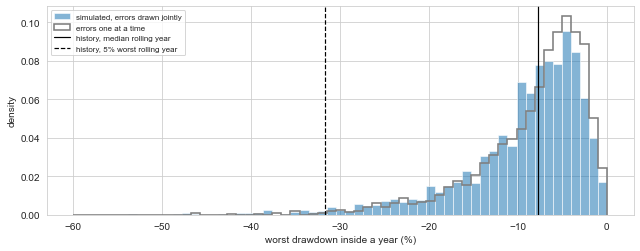

In [13]:
d_sim, d_indep = drawdown(Pa.array @ w_eq.values), drawdown(Pa_indep.array @ w_eq.values)
h = (R @ w_eq).values
d_hist = np.array([drawdown(h[s:s + H][None, :])[0] for s in range(len(h) - H + 1)])
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    bins = np.linspace(-0.6, 0, 60)
    ax.hist(d_sim * 100, bins=bins * 100, density=True, alpha=0.55, label="simulated, errors drawn jointly")
    ax.hist(d_indep * 100, bins=bins * 100, density=True, histtype="step", lw=1.6, color="tab:grey", label="errors one at a time")
    for q, ls in [(0.5, "-"), (0.05, "--")]:
        ax.axvline(np.quantile(d_hist, q) * 100, color="black", ls=ls, lw=1.2,
                   label=f"history, {'median' if q == 0.5 else '5% worst'} rolling year")
    ax.set_xlabel("worst drawdown inside a year (%)"); ax.set_ylabel("density"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

The joint draw sits to the left of the one-at-a-time draw over the whole
range, not only in the tail. The history's median falls inside the simulated
distribution; its 5 percent worst sits in the simulated distribution's thin
left shoulder.

---

<a id="s10"></a>
## 10. What this misses, and what comes next

<sub><a href="#toc">back to contents</a></sub>

The gap is in section 8's second table. The history's factor correlations rise
with the horizon, 0.61 to 0.78 for Credit against Equity DM, and the model's
stay flat. The reason is structural: the errors are i.i.d. in time by
construction, so the only dependence that survives cumulation is the one
inside a single month. A crisis that lasts nine months is not a month's
dependence repeated, it is a slow component the factors share, and nothing in
this construction carries one.

That is also why the drawdown tail is short, and it is the honest limit of the
whole course so far.

Two other things this notebook had to give up.

1. **Inflation and Credit have no clustering.** Section 5 took their GJR away
   to get a finite kurtosis, at 72 and 101 BIC units. A richer grid might
   find a model that is both stable and clustered; the one here did not.
2. **A factor without a history cannot be filtered.** Illiquidity and the two
   funds that loaded on it are out of this notebook. They belong to the
   cross-section of notebook 03.

**What takes it up.** Variables that share a slow component belong in one
block, filtered together rather than one at a time: a vector error-correction
model on the block, its innovations handed to the vine. That is
`examples/legacy/10_block_filters_vecm`, written against the previous
structure of the package, and the course notebook that will absorb it is the
next one to write.